# T019 · 分子动力学模拟

**说明：** 本教程属于 TeachOpenCADD 平台；该平台旨在教授领域专属技能，并提供可作为研究项目起点的流程模板。

**作者：**

- Pietro Gerletti，CADD seminar 2020，Charité/FU Berlin
- Mareike Leja，2020/21，Charité 的 [Volkamer Lab](https://volkamerlab.org/) 实习生
- Jeffrey R Wagner，2020，[Open Force Field Consortium](https://openforcefield.org/)
- David Schaller，2020/21，[Charité 的 Volkamer Lab](https://volkamerlab.org/)
- Andrea Volkamer，2020/21，[Charité 的 Volkamer Lab](https://volkamerlab.org/)

**中文版说明：** 本译本基于 TeachOpenCADD 上游仓库的固定版本 [commit 834b9ff59af69e8ba8d42aae23e92c15eb734ef0](https://github.com/volkamerlab/teachopencadd/commit/834b9ff59af69e8ba8d42aae23e92c15eb734ef0) 翻译整理；上游内容采用 [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) 许可。

__说明__

本教程原为配合 [Google Colab](https://colab.research.google.com/github/volkamerlab/teachopencadd/blob/1bd7cb0c9f6379aebc0c1a0b1c7413685910cffa/teachopencadd/talktorials/019_md_simulation/talktorial.ipynb) 使用而设计，也可以在本地计算机上运行。不过，如果没有 GPU，执行分子动力学模拟可能需要相当长的时间。

另请注意，目前本教程**无法在 Windows 上运行**（请在[此 issue](https://github.com/volkamerlab/teachopencadd/issues/136)中查看进展）。

## 本教程目标

本教程将介绍分子动力学（MD）模拟为何对药物设计很重要，以及模拟蛋白质-配体复合物需要哪些步骤。我们将以激酶 EGFR 作为示例系统。

### *理论*部分内容

- 分子动力学
- 力场
- 边界条件
- MD 模拟与药物设计
- EGFR 激酶

### *实践*部分内容

- 在 Google Colab 中安装
- 调整 Linux 或 macOS 本地安装的运行环境
- 导入依赖项
- 下载 PDB 文件
- 准备蛋白质-配体复合物
  - 蛋白质准备
  - 配体准备
  - 合并蛋白质与配体
- 设置 MD 模拟
  - 力场
  - 系统
- 执行 MD 模拟
- 下载结果

### 参考文献

- 关于 MD 模拟对药物发现影响的综述（[_J Med Chem_ (2016), **59**(9), 4035‐4061](https://doi.org/10.1021/acs.jmedchem.5b01684)）
- 关于 MD 模拟物理基础与最佳实践的综述（[_Living J Comp Mol Sci_ (2019), **1**(1), 5957](https://doi.org/10.33011/livecoms.1.1.5957)）
- 关于力场的综述（[_J Chem Inf Model_ (2018), **58**(3), 565-578](https://doi.org/10.1021/acs.jcim.8b00042)）
- 关于 EGFR 与癌症的综述（[_Cancers (Basel)_ (2017), **9**(5), 52](https://dx.doi.org/10.3390%2Fcancers9050052)）
- Pierre-Simon Laplace 统计学思想的总结（[Théorie Analytique des Probabilités _Gauthier-Villars_ (1820), **3**](https://archive.org/details/uvrescompltesde31fragoog/page/n15/mode/2up)）
- 灵感来自 Jaime Rodríguez-Guerra 的[笔记本](https://github.com/jaimergp/uab-msc-bioinf/blob/master/MD%20Simulation%20and%20Analysis%20in%20a%20Notebook.ipynb)
- [OpenMM](https://github.com/openmm/openmm) 与 [OpenMM Forcefields](https://github.com/openmm/openmmforcefields)、[RDKit](https://github.com/rdkit/rdkit)、[PyPDB](https://github.com/williamgilpin/pypdb)、[MDTraj](https://github.com/mdtraj/mdtraj)、[PDBFixer](https://github.com/openmm/pdbfixer) 的代码仓库
- 关于 [MD 模拟](https://en.wikipedia.org/wiki/Molecular_dynamics)、[AMBER](https://en.wikipedia.org/wiki/AMBER) 和[力场](https://en.wikipedia.org/wiki/Force_field_(chemistry))的一般性维基百科条目

In [1]:
import sys

on_colab = "google.colab" in sys.modules
if on_colab:
    %pip install teachopencadd --no-deps -q
    !teachopencadd -d 19
    %pip uninstall teachopencadd -y -q
    %pip install -qr requirements.txt
    %conda install mdtraj openmm openmmforcefields openff-toolkit pdbfixer pypdb rdkit -y -c conda-forge

## 理论

### 分子动力学

分子动力学是一种计算方法，用于分析给定系统中原子和分子的运动及相互作用。这一方法源于理论物理学，并于 20 世纪 50 年代发展起来（Alder 和 Wainwright，[_J Chem Phys_ (1959), **31**(2), 459](https://doi.org/10.1063/1.1730376)）；不过，其思想可以追溯到更早时期：

> 如果有一种智慧，能够在任何时刻理解自然界中一切力量及其所作用对象的相对位置；如果这种智慧又足够强大，能够分析这些数据，那么它就能用一个公式囊括宇宙中最大天体与最轻原子的运动。对它而言，没有任何事情是不确定的，未来与过去都尽在眼前。人类心智在天文学方面达到的完善程度，只不过是这种智慧的一个模糊缩影。（Pierre-Simon Laplace，1820）

我们可以把 Laplace 的这段话视为分子动力学模拟的思想基础。换言之，只要了解系统组成部分的特征并应用牛顿运动定律，就可以近似描述物理系统的行为。求解运动方程后，我们可以得到系统的分子轨迹；轨迹由一系列快照组成，记录所有粒子的位置和速度，以及系统的势能。为此，我们定义称为**力场**的函数，近似描述作用于系统中每个粒子的力，再使用数值积分器求解系统的初值问题，从而得到轨迹。正如所料，这一过程需要相当大的计算能力。直到近些年，MD 才开始得到更广泛的应用，尤其是在计算化学、生物学和药物发现领域（[_J Med Chem_ (2016), **59**(9), 4035‐4061](https://doi.org/10.1021/acs.jmedchem.5b01684)）。

![MD_rotor_250K_1ns.gif](https://github.com/volkamerlab/teachopencadd/raw/d1ded86bb2c82ef088cc5145d0bcb997f6eab7dd/teachopencadd/talktorials/018_md_simulation/images/MD_rotor_250K_1ns.gif)

**图 1**：由三个分子组成的超分子在受限纳米孔内旋转的分子动力学模拟（Palma 等人；图片来自 [Wikimedia](https://commons.wikimedia.org/w/index.php?curid=34866205)）。

### 力场

力场描述分子内和分子间原子所受的力。它们是由多个部分组成的参数化方程，分别描述不同的作用力（键伸缩、范德华力等）。参数通常由实验数据确定，并根据 MD 场景、涉及的分子和模拟设置而改变。最终，力场给出系统能量景观的数学描述；作用于每个粒子的力由势能对原子坐标的梯度确定。

目前有多种力场，各有特点（[_J Chem Inf Model_ (2018), **58**(3), 565-578](https://doi.org/10.1021/acs.jcim.8b00042)）。本笔记本将使用 AMBER 力场家族中的一种，它们广泛用于蛋白质 MD 模拟。其函数形式如下：

$$V(r^N) = \sum_{i \in  bonds}k_{bi} (l_i-l^0_i)^2 + \sum_{i \in  angles}k_{ai}(\theta_i - \theta^0_i)^2 + \sum_{i\in torsions} \sum_n \frac{1}{2} V_i^n[1+cos(nw_i-\gamma_i)]$$
$$+ \sum_{j=1}^{N-1}\sum_{I=j+1}^{N} f_{ij}\in ij [(\frac{r^0_{ij}}{r_{ij}})^{12}-2(\frac{r^0_{ij}}{r_{ij}})^{6}]+\frac{q_iq_j}{4\pi \in_0 r_{ij}}$$

公式由多个部分相加而成。前三项包含键长、键角和扭转角的信息（分子内作用力）；最后一项描述范德华力和静电相互作用等分子间非键合作用力。上标为 0 的参数取决于所使用的力场，在 AMBER 力场家族的不同成员之间也有所差异。请注意，这些力场假设粒子带有固定电荷，不允许极化，也不考虑局部电荷对周围环境的影响。

下面的力场组成部分示意图以更直观的方式展示了相同概念。

![MM_PEF.png](https://github.com/volkamerlab/teachopencadd/raw/d1ded86bb2c82ef088cc5145d0bcb997f6eab7dd/teachopencadd/talktorials/018_md_simulation/images/MM_PEF.png)

**图 2**：分子力学力场的组成部分（Edboas；图片来自 [Wikimedia](https://commons.wikimedia.org/w/index.php?curid=4194424)）。

### 边界条件

分子系统通常在装有水等溶剂的盒子中模拟。盒子的尺寸有限，因此位于边界处或附近的分子会带来问题：它们应该与哪些分子相互作用？周期性边界条件可以通过模拟理论上的无限系统来避免这类边界伪影。盒子一侧边界处的分子会与另一侧边界处的分子相互作用，这相当于模拟盒周围环绕着自身复制体的情形。观察这类 MD 模拟时，常会看到粒子从盒子一侧离开（图 3），但它们会以相同速度同时从另一侧重新出现。采用周期性边界条件时，建议使用足够大的模拟盒，避免模拟的大分子与其相邻的周期映像接触。

![MD_water.gif](https://github.com/volkamerlab/teachopencadd/raw/d1ded86bb2c82ef088cc5145d0bcb997f6eab7dd/teachopencadd/talktorials/018_md_simulation/images/MD_water.gif)

**图 3**：采用周期性边界条件的水分子分子动力学模拟（Kmckiern；图片来自 [Wikimedia](https://commons.wikimedia.org/wiki/File:MD_water.gif)）。

### MD 模拟与药物设计

MD 模拟能够帮助我们深入了解配体与靶标结合这一高度动态的过程。当配体（或药物）在溶液中接近大分子（蛋白质）时，它面对的是一个持续运动的结构。此外，配体可能诱导大分子发生构象变化，使其更好地容纳小分子。这些构象可能无法通过静态方法发现。因此，某些未出现在无配体静态结构中、但可通过 MD 模拟发现的结合位点，有时称为*隐蔽结合位点*（*cryptic binding sites*；[_J Med Chem_ (2016), **59**(9), 4035‐4061](https://doi.org/10.1021/acs.jmedchem.5b01684)）。通过 MD 模拟发现这类位点，可以为新的药物发现项目提供起点。在药物发现流程的后期，MD 模拟也可用于评估计算方法筛选出的小分子的质量，再决定是否开展成本更高、耗时更长的*体外*实验。总的来说，MD 模拟是计算机辅助药物设计的重要工具。

### EGFR 激酶

**表皮生长因子受体**（**E**pidermal **G**rowth **F**actor **R**eceptor，EGFR）是重要的药物靶标，与癌症和炎症有关（[Wikipedia](https://en.wikipedia.org/wiki/Epidermal_growth_factor_receptor)）。它是一种跨膜蛋白，包含细胞外受体结构域和细胞内激酶结构域。内源性配体表皮生长因子与其结合后，会通过二聚化和自磷酸化激活激酶结构域。活化的激酶结构域随后可磷酸化下游信号蛋白，触发 DNA 合成和细胞增殖（[_Cancers (Basel)_ (2017), **9**(5), 52](https://dx.doi.org/10.3390%2Fcancers9050052)）。多种已获批抗癌药物的作用机制就是抑制这一激酶（[DrugBank](https://go.drugbank.com/bio_entities/BE0000767)）。本教程将使用该激酶与小分子抑制剂 **03P** 形成复合物的 PDB 结构 **3POZ** 进行 MD 模拟（[PDB: 3POZ](https://www.rcsb.org/structure/3poz)）。

![3poz_assembly-1.jpeg](https://github.com/volkamerlab/teachopencadd/raw/ed3b2b6b655589d71355295af4c89363a63558b9/teachopencadd/talktorials/018_md_simulation/images/3poz_assembly-1.jpeg)

**图 4**：与抑制剂 03P 结合的 EGFR 激酶结构域结构 3POZ（[PDB: 3POZ](https://www.rcsb.org/structure/3poz)）。

## 实践

接下来，我们将使用分子动力学引擎 [OpenMM](https://github.com/openmm/openmm) 执行 MD 模拟。OpenMM 是用于分子模拟的高性能工具包，采用开源许可，既可作为应用程序使用，也可作为程序库使用。本教程将把它作为 Python 程序库使用。

### 导入依赖项

In [2]:
import copy
from pathlib import Path

import requests
from IPython.display import display
import numpy as np
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem
import mdtraj as md
import pdbfixer
import openmm as mm
import openmm.app as app
from openmm import unit
from openff.toolkit.topology import Molecule, Topology
from openmmforcefields.generators import GAFFTemplateGenerator

In [3]:
# create data directory if not exists
HERE = Path(_dh[-1])
DATA = HERE / "data"
DATA.mkdir(exist_ok=True)

### 下载 PDB 文件
[蛋白质数据库](https://www.rcsb.org/)（PDB）支持通过 URL 轻松下载文件。

In [4]:
pdbid = "3POZ"
ligand_name = "03P"
pdb_path = DATA / f"{pdbid}.pdb"
pdb_url = f"https://files.rcsb.org/download/{pdbid}.pdb"

In [5]:
r = requests.get(pdb_url)
r.raise_for_status()
with open(pdb_path, "wb") as f:
    f.write(r.content)

### 准备蛋白质-配体复合物

#### 蛋白质准备

要成功完成模拟，系统必须正确且完整。从蛋白质数据库获取的晶体结构通常会缺少原子（主要是氢原子），也可能含有非标准残基。本教程将使用 Python 软件包 [PDBFixer](https://github.com/openmm/pdbfixer) 准备蛋白质结构。不过，[PDBFixer](https://github.com/openmm/pdbfixer) 对共晶配体的处理效果不佳，因此我们会单独准备配体。

In [6]:
def prepare_protein(
    pdb_file, ignore_missing_residues=True, ignore_terminal_missing_residues=True, ph=7.0
):
    """
    Use pdbfixer to prepare the protein from a PDB file. Hetero atoms such as ligands are
    removed and non-standard residues replaced. Missing atoms to existing residues are added.
    Missing residues are ignored by default, but can be included.

    Parameters
    ----------
    pdb_file: pathlib.Path or str
        PDB file containing the system to simulate.
    ignore_missing_residues: bool, optional
        If missing residues should be ignored or built.
    ignore_terminal_missing_residues: bool, optional
        If missing residues at the beginning and the end of a chain should be ignored or built.
    ph: float, optional
        pH value used to determine protonation state of residues

    Returns
    -------
    fixer: pdbfixer.pdbfixer.PDBFixer
        Prepared protein system.
    """
    fixer = pdbfixer.PDBFixer(str(pdb_file))
    fixer.removeHeterogens()  # co-crystallized ligands are unknown to PDBFixer
    fixer.findMissingResidues()  # identify missing residues, needed for identification of missing atoms

    # if missing terminal residues shall be ignored, remove them from the dictionary
    if ignore_terminal_missing_residues:
        chains = list(fixer.topology.chains())
        keys = fixer.missingResidues.keys()
        for key in list(keys):
            chain = chains[key[0]]
            if key[1] == 0 or key[1] == len(list(chain.residues())):
                del fixer.missingResidues[key]

    # if all missing residues shall be ignored ignored, clear the dictionary
    if ignore_missing_residues:
        fixer.missingResidues = {}

    fixer.findNonstandardResidues()  # find non-standard residue
    fixer.replaceNonstandardResidues()  # replace non-standard residues with standard one
    fixer.findMissingAtoms()  # find missing heavy atoms
    fixer.addMissingAtoms()  # add missing atoms and residues
    fixer.addMissingHydrogens(ph)  # add missing hydrogens
    return fixer

In [7]:
# prepare protein and build only missing non-terminal residues
prepared_protein = prepare_protein(pdb_path, ignore_missing_residues=False)

#### 配体准备

准备好蛋白质后，接下来处理配体。同样需要添加氢原子，并确保键级正确，因为部分 PDB 条目可能存在错误。我们将使用开源化学信息学软件包 [RDKit](https://github.com/rdkit/rdkit)。
我们会通过 SMILES 字符串向 [RDKit](https://github.com/rdkit/rdkit) 提供正确的质子化状态和键级。每个共晶配体的未带电异构 SMILES 字符串可在相应的 [PDB](https://www.rcsb.org) 条目中找到。PDB 条目 [3POZ](https://www.rcsb.org/structure/3poz) 中的配体名为 [03P](https://www.rcsb.org/ligand/03P)。如果配体可能以带电形式或特定互变异构体结合，就需要在 SMILES 字符串中体现这些特征。

In [8]:
def prepare_ligand(pdb_file, resname, smiles, depict=True):
    """
    Prepare a ligand from a PDB file via adding hydrogens and assigning bond orders. A depiction
    of the ligand before and after preparation is rendered in 2D to allow an inspection of the
    results. Huge thanks to @j-wags for the suggestion.

    Parameters
    ----------
    pdb_file: pathlib.PosixPath
       PDB file containing the ligand of interest.
    resname: str
        Three character residue name of the ligand.
    smiles : str
        SMILES string of the ligand informing about correct protonation and bond orders.
    depict: bool, optional
        show a 2D representation of the ligand

    Returns
    -------
    prepared_ligand: rdkit.Chem.rdchem.Mol
        Prepared ligand.
    """
    # split molecule
    rdkit_mol = Chem.MolFromPDBFile(str(pdb_file))
    rdkit_mol_split = Chem.rdmolops.SplitMolByPDBResidues(rdkit_mol)

    # extract the ligand and remove any already present hydrogens
    ligand = rdkit_mol_split[resname]
    ligand = Chem.RemoveHs(ligand)

    # assign bond orders from template
    reference_mol = Chem.MolFromSmiles(smiles)
    prepared_ligand = AllChem.AssignBondOrdersFromTemplate(reference_mol, ligand)
    prepared_ligand.AddConformer(ligand.GetConformer(0))

    # protonate ligand
    prepared_ligand = Chem.rdmolops.AddHs(prepared_ligand, addCoords=True)
    prepared_ligand = Chem.MolFromMolBlock(Chem.MolToMolBlock(prepared_ligand))

    # 2D depiction
    if depict:
        ligand_2d = copy.deepcopy(ligand)
        prepared_ligand_2d = copy.deepcopy(prepared_ligand)
        AllChem.Compute2DCoords(ligand_2d)
        AllChem.Compute2DCoords(prepared_ligand_2d)
        display(
            Draw.MolsToGridImage(
                [ligand_2d, prepared_ligand_2d], molsPerRow=2, legends=["original", "prepared"]
            )
        )

    # return ligand
    return prepared_ligand

使用从 PDB 条目 [03P](https://www.rcsb.org/ligand/03P) 获取的异构 SMILES 字符串调用该函数，可以得到正确准备的配体。输出中会显示原始配体和处理后配体的二维表示，便于检查。

[10:10:57] WARNING: More than one matching pattern found - picking one



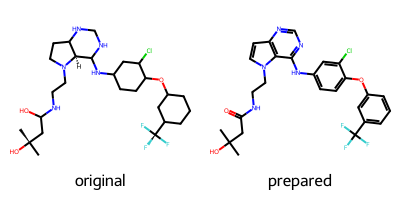

In [9]:
smiles = "CC(C)(O)CC(=O)NCCn1ccc2ncnc(Nc3ccc(Oc4cccc(c4)C(F)(F)F)c(Cl)c3)c12"
rdkit_ligand = prepare_ligand(pdb_path, ligand_name, smiles)

#### 合并蛋白质与配体

下一步将使用 Python 软件包 [MDTraj](https://github.com/mdtraj/mdtraj) 合并准备好的蛋白质和配体结构。[MDTraj](https://github.com/mdtraj/mdtraj) 可以处理准备后的蛋白质；此时它还是一个 [PDBFixer](https://github.com/openmm/pdbfixer) 分子，其拓扑和原子位置格式与 [OpenMM Modeller](http://docs.openmm.org/latest/userguide/application.html#model-building-and-editing) 的拓扑和位置相似，通常可以互换使用。不过，配体目前是一个 [RDKit](https://github.com/rdkit/rdkit) 分子，因此还需要进行几次格式转换。

In [10]:
def rdkit_to_openmm(rdkit_mol, name="LIG"):
    """
    Convert an RDKit molecule to an OpenMM molecule.
    Inspired by @hannahbrucemcdonald and @glass-w.

    Parameters
    ----------
    rdkit_mol: rdkit.Chem.rdchem.Mol
        RDKit molecule to convert.
    name: str
        Molecule name.

    Returns
    -------
    omm_molecule: openmm.app.Modeller
        OpenMM modeller object holding the molecule of interest.
    """
    # convert RDKit to OpenFF
    off_mol = Molecule.from_rdkit(rdkit_mol)

    # add name for molecule
    off_mol.name = name

    # add names for atoms
    element_counter_dict = {}
    for off_atom, rdkit_atom in zip(off_mol.atoms, rdkit_mol.GetAtoms()):
        element = rdkit_atom.GetSymbol()
        if element in element_counter_dict.keys():
            element_counter_dict[element] += 1
        else:
            element_counter_dict[element] = 1
        off_atom.name = element + str(element_counter_dict[element])

    # convert from OpenFF to OpenMM
    off_mol_topology = off_mol.to_topology()
    mol_topology = off_mol_topology.to_openmm()
    mol_positions = off_mol.conformers[0]

    # convert units from Ångström to nanometers
    # since OpenMM works in nm
    mol_positions = mol_positions.to("nanometers")

    # combine topology and positions in modeller object
    omm_mol = app.Modeller(mol_topology, mol_positions)

    return omm_mol

In [11]:
omm_ligand = rdkit_to_openmm(rdkit_ligand, ligand_name)

现在，蛋白质和配体都已转换为与 [OpenMM](https://github.com/openmm/openmm) 兼容的格式，可以使用 [MDTraj](https://github.com/mdtraj/mdtraj) 将它们合并。

In [12]:
def merge_protein_and_ligand(protein, ligand):
    """
    Merge two OpenMM objects.

    Parameters
    ----------
    protein: pdbfixer.pdbfixer.PDBFixer
        Protein to merge.
    ligand: openmm.app.Modeller
        Ligand to merge.

    Returns
    -------
    complex_topology: openmm.app.topology.Topology
        The merged topology.
    complex_positions: openmm.unit.quantity.Quantity
        The merged positions.
    """
    # combine topologies
    md_protein_topology = md.Topology.from_openmm(protein.topology)  # using mdtraj for protein top
    md_ligand_topology = md.Topology.from_openmm(ligand.topology)  # using mdtraj for ligand top
    md_complex_topology = md_protein_topology.join(md_ligand_topology)  # add them together
    complex_topology = md_complex_topology.to_openmm()

    # combine positions
    total_atoms = len(protein.positions) + len(ligand.positions)

    # create an array for storing all atom positions as tupels containing a value and a unit
    # called OpenMM Quantities
    complex_positions = unit.Quantity(np.zeros([total_atoms, 3]), unit=unit.nanometers)
    complex_positions[: len(protein.positions)] = protein.positions  # add protein positions
    complex_positions[len(protein.positions) :] = ligand.positions  # add ligand positions

    return complex_topology, complex_positions

In [13]:
complex_topology, complex_positions = merge_protein_and_ligand(prepared_protein, omm_ligand)

/home/michael/.teachopencadd_envs/teachopencadd_T019_py312/lib/python3.12/site-packages/openmm/unit/quantity.py:750: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  self._value[key] = value / self.unit


In [14]:
print("Complex topology has", complex_topology.getNumAtoms(), "atoms.")
# NBVAL_CHECK_OUTPUT

Complex topology has 5561 atoms.


### 设置 MD 模拟

现在可以使用准备好的复合物设置 MD 模拟。

#### 力场

常见的力场（如 AMBER）包含氨基酸、核酸、水和离子的参数，通常还提供多种选项，以适应不同的模拟目标。我们将使用 OpenMM 自带的 <code>amber14-all.xml</code> 力场文件，其中包含蛋白质、DNA、RNA 和脂质的参数。溶剂化时使用标准三点式[水模型](https://en.wikipedia.org/wiki/Water_model) [**TIP3P**](https://aip.scitation.org/doi/10.1063/1.445869)。

力场文件中不包含配体参数。为生成这些参数，我们可以使用 [OpenMM Forcefields](https://github.com/openmm/openmmforcefields) Python 软件包所实现的**通用 AMBER 力场**（**G**eneral **A**MBER **F**orce**F**ield， [GAFF](http://ambermd.org/antechamber/gaff.html)）。下面的函数会生成力场对象，其中包含标准 AMBER 参数，并在需要时加入小分子的参数。

In [15]:
def generate_forcefield(
    rdkit_mol=None, protein_ff="amber14-all.xml", solvent_ff="amber14/tip3pfb.xml"
):
    """
    Generate an OpenMM Forcefield object and register a small molecule.

    Parameters
    ----------
    rdkit_mol: rdkit.Chem.rdchem.Mol
        Small molecule to register in the force field.
    protein_ff: string
        Name of the force field.
    solvent_ff: string
        Name of the solvent force field.

    Returns
    -------
    forcefield: openmm.app.Forcefield
        Forcefield with registered small molecule.
    """
    forcefield = app.ForceField(protein_ff, solvent_ff)

    if rdkit_mol is not None:
        gaff = GAFFTemplateGenerator(
            forcefield="gaff-2.2.20",
            molecules=Molecule.from_rdkit(rdkit_mol, allow_undefined_stereo=True),
        )
        forcefield.registerTemplateGenerator(gaff.generator)

    return forcefield

In [16]:
forcefield = generate_forcefield(rdkit_ligand)

#### 系统

配置好力场后，我们就可以使用 [OpenMM Modeller](http://docs.openmm.org/latest/userguide/application.html#model-building-and-editing) 类创建 MD 环境：一个包含复合物并充满溶剂的模拟盒。标准溶剂是水，并含有指定数量的离子。确定模拟盒尺寸有多种方法；这里采用填充距离（padding），生成一个立方体盒，其尺寸取决于复合物的最大跨度。

> 请注意，根据硬件不同，这一步可能耗时较长，约需数分钟。

In [17]:
modeller = app.Modeller(complex_topology, complex_positions)
modeller.addSolvent(forcefield, padding=1.0 * unit.nanometers, ionicStrength=0.15 * unit.molar)

有了溶剂化后的系统和力场，最后就可以创建 [OpenMM System](http://docs.openmm.org/development/api-python/generated/openmm.openmm.System.html#openmm.openmm.System) 并设置模拟。

除 system 外，模拟还需要一个积分器。[OpenMM Integrator](http://docs.openmm.org/development/api-python/library.html#integrators) 通过积分运动方程定义系统的模拟方法。本教程选择的**朗之万积分器**使用朗之万方程。不同积分器的列表见 [OpenMM 文档](http://docs.openmm.org/development/api-python/library.html#integrators)。若想进一步了解**朗之万积分器**，建议阅读朗之万方程的相关资料，例如 [Wikipedia](https://en.wikipedia.org/wiki/Langevin_equation)。

In [18]:
system = forcefield.createSystem(modeller.topology, nonbondedMethod=app.PME)
integrator = mm.LangevinIntegrator(
    300 * unit.kelvin, 1.0 / unit.picoseconds, 2.0 * unit.femtoseconds
)
simulation = app.Simulation(modeller.topology, system, integrator)
simulation.context.setPositions(modeller.positions)

### 执行 MD 模拟

所有内容设置完成后，就可以运行模拟了。我们需要设置初始位置并最小化系统能量，以获得低能量的起始构型，从而降低严重原子冲突导致模拟失败的可能性。最小化后的系统会保存下来。

In [19]:
simulation.minimizeEnergy()
with open(DATA / "topology.pdb", "w") as pdb_file:
    app.PDBFile.writeFile(
        simulation.topology,
        simulation.context.getState(getPositions=True, enforcePeriodicBox=True).getPositions(),
        file=pdb_file,
        keepIds=True,
    )

能量最小化完成后，就可以运行 MD 模拟。本教程只进行一段较短的演示模拟。研究用途的模拟通常持续数纳秒，甚至可达微秒级。这里仅模拟 100 ps，对应 50k 个时间步，每步 2 fs。每隔 10 ps（5000 步）保存一个分子“快照”，总共保存 10 帧。结果保存在 <code>.xtc</code> 文件中，其中记录各时间点所有原子的坐标。加上之前写出的能量最小化系统 PDB 文件，就包含了后续分析所需的全部信息。

**注意：** 如果不在 Google Colab 中运行，本教程只会生成 20 fs 的轨迹。不过，如果有性能良好的 GPU，也可以增加模拟时长。

In [20]:
# output settings
if on_colab:
    steps = 50000  # corresponds to 100 ps
    write_interval = 5000  # write every 10 ps
    log_interval = 2500  # log progress to stdout every 5 ps
else:
    steps = 10  # corresponds to 20 fs
    write_interval = 1  # write every 2 fs
    log_interval = 1  # log progress to stdout every 2 fs
simulation.reporters.append(
    md.reporters.XTCReporter(file=str(DATA / "trajectory.xtc"), reportInterval=write_interval)
)
simulation.reporters.append(
    app.StateDataReporter(
        sys.stdout,
        log_interval,
        step=True,
        potentialEnergy=True,
        temperature=True,
        progress=True,
        remainingTime=True,
        speed=True,
        totalSteps=steps,
        separator="\t",
    )
)

系统中所有粒子的速度都从给定温度对应的分布中随机抽取。这里选择 300 Kelvin，比室温略高一些。
我们会生成一个随机种子；也可以显式指定种子以便复现结果。

接下来，按照前面定义的步数执行模拟。

In [21]:
simulation.context.setVelocitiesToTemperature(300 * unit.kelvin)
simulation.step(steps)  # perform the simulation

#"Progress (%)"	"Step"	"Potential Energy (kJ/mole)"	"Temperature (K)"	"Speed (ns/day)"	"Time Remaining"
10.0%	1	-911672.8833984158	300.58994432283663	0	--
20.0%	2	-898806.4210639504	267.2506776332451	1.78	0:00
30.0%	3	-883111.4814176012	238.60290950665717	1.73	0:00
40.0%	4	-867596.4630740668	196.76725273444427	1.68	0:00
50.0%	5	-862553.2471993582	175.87229216182052	1.6	0:00
60.0%	6	-854763.8296435549	163.39398429953755	1.54	0:00
70.0%	7	-852074.9736099411	147.9384677561452	1.5	0:00
80.0%	8	-855085.7518770137	152.24611569256365	1.5	0:00
90.0%	9	-856760.1494785415	157.91401106119835	1.49	0:00
100.0%	10	-861616.5007841537	165.39716192526913	1.49	0:00


In [22]:
# Check the trajectory exists and is not empty
(DATA / "trajectory.xtc").stat().st_size > 0
# NBVAL_CHECK_OUTPUT

True

### 下载结果

如果你在 Google Colab 中运行，可以执行下面的代码单元下载 MD 模拟结果。

In [23]:
if on_colab:
    files.download(DATA / "topology.pdb")
    files.download(DATA / "trajectory.xtc")

## 讨论

我们已成功对蛋白质-配体复合物进行了 MD 模拟。不过，为了缩短教程运行时间，我们只模拟了相当短的一段时间。研究药物设计中的关键问题时，往往需要更长的模拟。
MD 模拟的计算成本仍然很高，因此人们开发了旨在加速构象采样的增强采样方法。下面的**延伸阅读**部分介绍了几种常见方法。
此外，本教程未设置平衡步骤。平衡阶段通常会在正式模拟前将系统缓慢升温至 300 K；对于脂质双层等较敏感体系，这一步可能很重要。配体和蛋白质分别进行了质子化处理，这并不理想，因为蛋白质残基和配体的质子化状态会相互影响。不过，我们没有找到能够满足所有要求的免费开源解决方案。欢迎提出建议！
若想了解如何可视化和分析轨迹，请参阅本仓库的 **Talktorial T020**。

## 测验

- AMBER 力场考虑了哪些分子间和分子内作用力？你能想到哪些未纳入的作用力吗？
- 使用相同参数运行两次笔记本时，你预期会得到完全相同的模拟结果吗？
- 尝试对一个不含配体的蛋白质进行短模拟（10 ps，每 1 ps 保存一帧）。你可以从 [PDB](https://www.rcsb.org/) 中选择各种结构，也可以使用 EGFR 激酶并移除配体。

## 延伸阅读

### 增强采样方法

理论上，无偏 MD 模拟应当能够模拟药物分子与其大分子靶标的结合和解离事件。然而，结合和解离通常发生在毫秒至秒的时间尺度上。增强采样方法旨在加速构象采样（[_J Med Chem._ 2016, **59(9)**, 4035-61](https://doi.org/10.1021/acs.jmedchem.5b01684)）。

其中一种方法是**自由能微扰**（**F**ree **E**nergy **P**erturbation，FEP；也称为炼金自由能计算），用于计算从状态 A 转变至状态 B 时的自由能差。它常用于先导化合物优化，评估配体上的微小修饰是否会提高其对目标的结合亲和力。具体而言，通过模拟多个中间（“炼金”）状态，将状态 A 的配体逐步转变为状态 B 的配体（[alchemistry](http://www.alchemistry.org/wiki/Main_Page)）。

另一种自由能计算技术是**伞形采样**（Umbrella Sampling，US）。伞形采样通过施加能量偏置的分阶段模拟，沿集体变量（CV）强制进行采样。该偏置通常采用谐和势，因此称为“伞形”。其目标是采样集体变量方向上的高能区域。不过，由于计算成本很高，它在药物设计中的应用有限。

**牵引 MD**（Steered MD，SMD）采用不同思路：对系统施加外力。外力随时间变化，促使配体从靶标中解离。SMD 会计算作用于系统的最终力。随后可以利用解离力曲线筛选对接获得的命中分子，并区分活性与非活性分子。